# 03 — Experimentación integral y selección del modelo de forecasting
**Caso Tostao | Demanda diaria por SKU–tienda | Horizonte de 7 días**

## Objetivo
Este notebook consolida en un único flujo la experimentación de forecasting realizada en los notebooks 03, 03A y 03B. Compara modelos estadísticos y de machine learning, evalúa su desempeño con backtesting temporal y documenta la decisión del modelo que alimenta el pipeline de abastecimiento y la aplicación Streamlit.

**Modelos incluidos**
1. Naive.
2. Seasonal Naive 7.
3. Moving Average 7.
4. ETS aditivo con estacionalidad semanal.
5. SARIMA estacional (7).
6. Random Forest global (pooled).
7. XGBoost global (direct multi-horizon).

**Decisión de despliegue vigente:** ETS aditivo por SKU–tienda. XGBoost queda como challenger. La selección no se basa exclusivamente en el menor WAPE: considera magnitud de la mejora, RMSE, sesgo, estabilidad entre folds, complejidad y facilidad de operación.

> Nota de rigor: el benchmark consolidado histórico reportó resultados obtenidos en ejecuciones anteriores. Este notebook vuelve a ejecutar los experimentos sobre los mismos datos y folds para producir una comparación homogénea. Los valores históricos se conservan aparte como referencia documental, no se mezclan con los resultados recién ejecutados.

## 1. Configuración y carga de datos

In [1]:
# En Google Colab, instala las dependencias si hacen falta.
!pip -q install statsmodels holidays xgboost

In [3]:
import os, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
HORIZON = 7
N_FOLDS = 3
MIN_HISTORY = 28

In [4]:
# Carga flexible: Colab solicita archivos faltantes; local usa la carpeta data/.
try:
    from google.colab import files
    IN_COLAB = True
except Exception:
    IN_COLAB = False

required_files = [
    "ventas_historicas.csv", "inventario_actual.csv",
    "catalogo_productos.csv", "maestro_tiendas.csv"
]
DATA_DIR = Path("data")
if not all((DATA_DIR/f).exists() for f in required_files):
    if IN_COLAB:
        uploaded = files.upload()
        DATA_DIR = Path(".")
    else:
        raise FileNotFoundError("Ubica los cuatro CSV en la carpeta data/ o en el directorio actual.")

def find_data(name):
    for base in [DATA_DIR, Path("."), Path("/content")]:
        p = base/name
        if p.exists():
            return p
    raise FileNotFoundError(name)

ventas = pd.read_csv(find_data("ventas_historicas.csv"))
inventario = pd.read_csv(find_data("inventario_actual.csv"))
productos = pd.read_csv(find_data("catalogo_productos.csv"))
tiendas = pd.read_csv(find_data("maestro_tiendas.csv"))

ventas["fecha"] = pd.to_datetime(ventas["fecha"], errors="raise")
ventas["unidades_vendidas"] = pd.to_numeric(ventas["unidades_vendidas"], errors="coerce").fillna(0).clip(lower=0)
print("Ventas:", ventas.shape)
print("Periodo:", ventas.fecha.min().date(), "a", ventas.fecha.max().date())
print("Tiendas:", ventas.id_tienda.nunique(), "| Productos:", ventas.id_producto.nunique())

Saving catalogo_productos.csv to catalogo_productos (2).csv
Saving inventario_actual.csv to inventario_actual (2).csv
Saving ventas_historicas.csv to ventas_historicas (2).csv
Saving maestro_tiendas.csv to maestro_tiendas (2).csv
Ventas: (14560, 4)
Periodo: 2024-01-01 a 2024-03-31
Tiendas: 20 | Productos: 8


## 2. Construcción del panel diario SKU–tienda

Se genera un calendario diario para cada combinación observada. En este ejercicio, la ausencia de registro se completa como cero ventas, siguiendo el supuesto utilizado en los experimentos previos. En un entorno productivo debe distinguirse cero demanda de quiebre de inventario o falla de captura.

In [5]:
KEYS = ["id_tienda", "id_producto"]
combos = ventas[KEYS].drop_duplicates()
calendar = pd.DataFrame({"fecha": pd.date_range(ventas.fecha.min(), ventas.fecha.max(), freq="D")})
panel = combos.merge(calendar, how="cross")
daily = ventas.groupby(KEYS+["fecha"], as_index=False)["unidades_vendidas"].sum()
panel = panel.merge(daily, on=KEYS+["fecha"], how="left")
panel["y"] = panel["unidades_vendidas"].fillna(0).clip(lower=0)
panel = panel.drop(columns="unidades_vendidas")
panel = panel.merge(productos, on="id_producto", how="left").merge(tiendas, on="id_tienda", how="left")
panel = panel.sort_values(KEYS+["fecha"]).reset_index(drop=True)
panel["dow"] = panel.fecha.dt.dayofweek
panel["weekend"] = (panel.dow >= 5).astype(int)
panel["dow_sin"] = np.sin(2*np.pi*panel.dow/7)
panel["dow_cos"] = np.cos(2*np.pi*panel.dow/7)
try:
    import holidays
    years = range(panel.fecha.dt.year.min(), panel.fecha.dt.year.max()+2)
    CO_HOLIDAYS = holidays.country_holidays("CO", years=years, observed=True)
    panel["holiday"] = panel.fecha.dt.date.isin(CO_HOLIDAYS).astype(int)
except Exception:
    CO_HOLIDAYS = {}
    panel["holiday"] = 0

print("Panel:", panel.shape, "| series:", panel[KEYS].drop_duplicates().shape[0])
display(panel.head())

Panel: (14560, 16) | series: 160


,id_tienda,id_producto,fecha,y,nombre,categoria,costo_unitario,precio_venta,costo_almacenamiento_semanal,ciudad,tamaño_m2,dow,weekend,dow_sin,dow_cos,holiday
0,STORE_01,PROD_001,2024-01-01,5,Tinto,Bebidas,800,2500,10,Bogotá,28,0,0,0.000000,1.000000,1
1,STORE_01,PROD_001,2024-01-02,4,Tinto,Bebidas,800,2500,10,Bogotá,28,1,0,0.781831,0.623490,0
2,STORE_01,PROD_001,2024-01-03,3,Tinto,Bebidas,800,2500,10,Bogotá,28,2,0,0.974928,-0.222521,0
3,STORE_01,PROD_001,2024-01-04,4,Tinto,Bebidas,800,2500,10,Bogotá,28,3,0,0.433884,-0.900969,0
4,STORE_01,PROD_001,2024-01-05,10,Tinto,Bebidas,800,2500,10,Bogotá,28,4,0,-0.433884,-0.900969,0


## 2A. Insights exploratorios conservados del análisis original

Se mantienen los diagnósticos que ayudaron a entender la demanda antes de modelar: evolución diaria total, patrón por día de semana, distribución de ventas y diferencias entre productos y tiendas. Estos gráficos son descriptivos; no prueban causalidad.

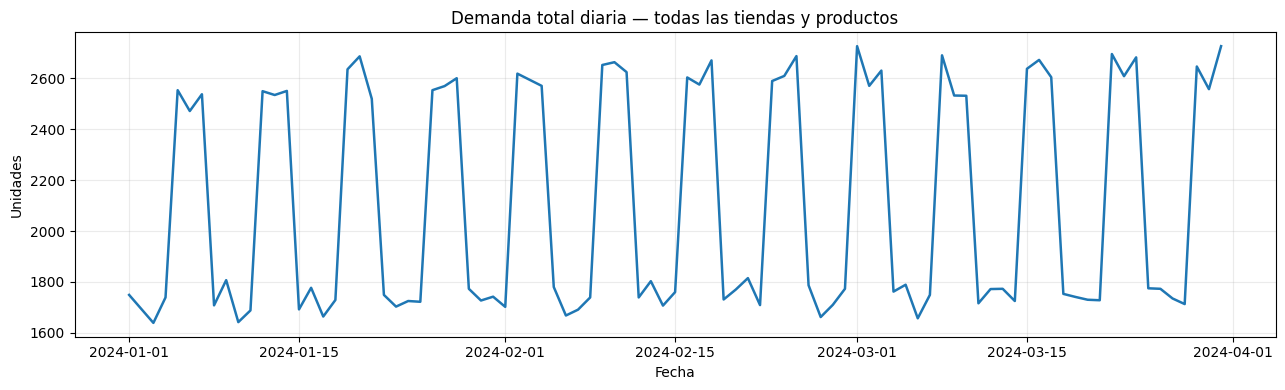

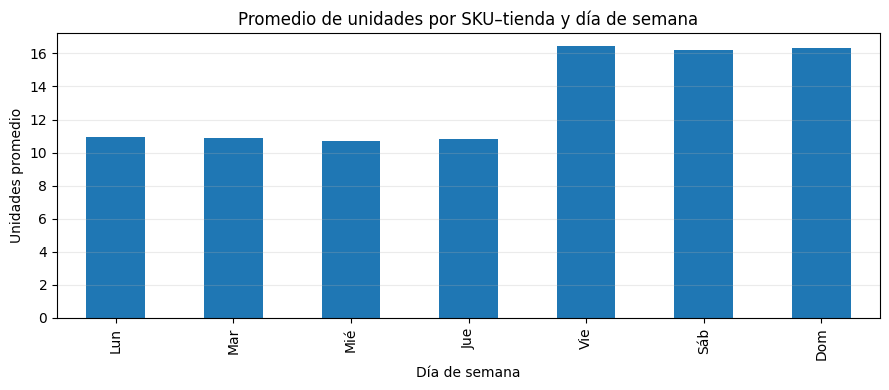

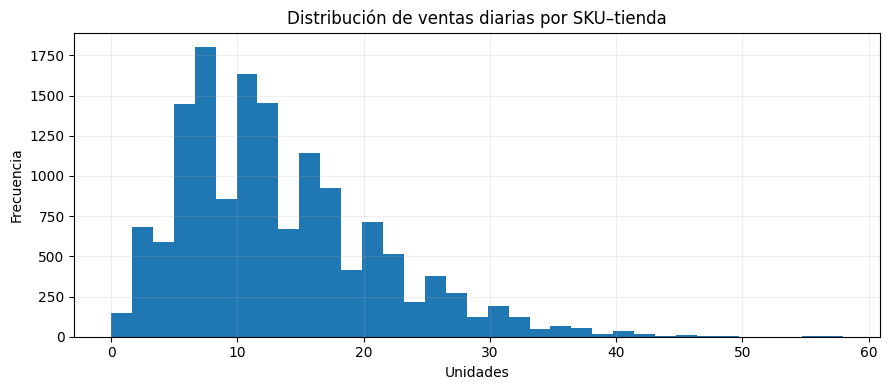

,id_producto,media_diaria,p90_diario,dias_cero
4,PROD_005,17.851099,29.0,0.001099
6,PROD_007,17.290659,29.0,0.000000
7,PROD_008,16.391758,27.0,0.000000
5,PROD_006,15.876374,26.0,0.000000
2,PROD_003,11.675275,20.0,0.000549
1,PROD_002,11.307692,19.0,0.000000
0,PROD_001,8.225824,14.0,0.004945
3,PROD_004,6.799451,12.0,0.007692


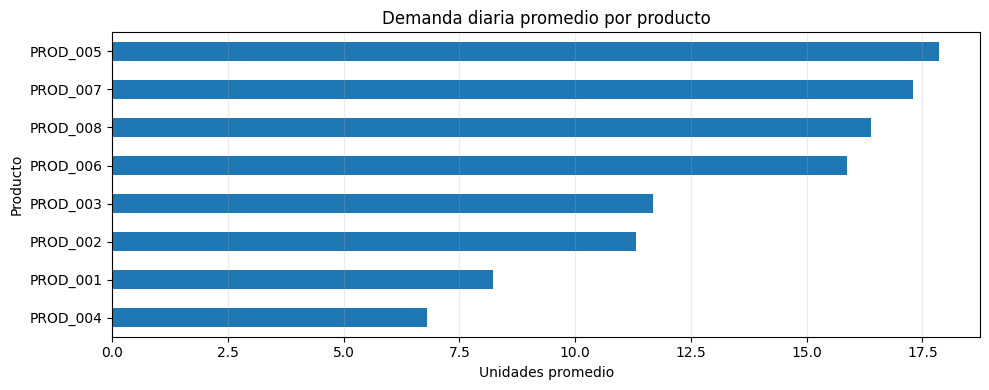

,ciudad,y
1,Cali,15.495879
0,Bogotá,13.744113
2,Medellín,11.126374


In [6]:
# Evolución de la demanda total diaria
daily_total = panel.groupby("fecha", as_index=False)["y"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_total["fecha"], daily_total["y"], linewidth=1.8)
ax.set_title("Demanda total diaria — todas las tiendas y productos")
ax.set_xlabel("Fecha"); ax.set_ylabel("Unidades")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

# Promedio diario por SKU–tienda según día de semana
weekday = panel.groupby("dow")["y"].mean().reindex(range(7))
weekday.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(figsize=(9, 4))
weekday.plot(kind="bar", ax=ax)
ax.set_title("Promedio de unidades por SKU–tienda y día de semana")
ax.set_xlabel("Día de semana"); ax.set_ylabel("Unidades promedio")
ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

# Distribución de demanda diaria (incluye ceros)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(panel["y"], bins=35)
ax.set_title("Distribución de ventas diarias por SKU–tienda")
ax.set_xlabel("Unidades"); ax.set_ylabel("Frecuencia")
ax.grid(alpha=.2); plt.tight_layout(); plt.show()

# Variabilidad por producto: promedio y percentil 90 diario
product_profile = (panel.groupby(["id_producto"], as_index=False)
                   .agg(media_diaria=("y","mean"), p90_diario=("y",lambda s:s.quantile(.90)),
                        dias_cero=("y",lambda s:(s==0).mean())))
display(product_profile.sort_values("media_diaria",ascending=False))
fig, ax = plt.subplots(figsize=(10, 4))
product_profile.sort_values("media_diaria").plot(x="id_producto",y="media_diaria",kind="barh",ax=ax,legend=False)
ax.set_title("Demanda diaria promedio por producto"); ax.set_xlabel("Unidades promedio"); ax.set_ylabel("Producto")
ax.grid(axis="x",alpha=.25); plt.tight_layout(); plt.show()

# Perfil por ciudad si está disponible
if "ciudad" in panel.columns:
    city_profile = panel.groupby("ciudad",as_index=False)["y"].mean().sort_values("y",ascending=False)
    display(city_profile)


## 3. Backtesting temporal común

Se evalúan los últimos 21 días mediante tres folds consecutivos de siete días. Todos los modelos reciben el mismo origen temporal y el mismo conjunto de prueba. Ninguna variable de entrenamiento utiliza información posterior al origen del fold.

In [7]:
all_dates = pd.DatetimeIndex(sorted(panel.fecha.unique()))
if len(all_dates) < 70:
    raise ValueError("Se requieren al menos 70 días para el backtesting configurado.")
folds = []
for fold_num in range(1, N_FOLDS+1):
    test_start = all_dates[-(N_FOLDS-fold_num+1)*HORIZON]
    test_end = test_start + pd.Timedelta(days=HORIZON-1)
    train_end = test_start - pd.Timedelta(days=1)
    folds.append({
        "fold": fold_num, "origin": train_end,
        "test_start": test_start, "test_end": test_end,
        "test_dates": pd.date_range(test_start, test_end, freq="D")
    })
folds_df = pd.DataFrame([{k:v for k,v in f.items() if k!="test_dates"} for f in folds])
display(folds_df)

,fold,origin,test_start,test_end
0,1,2024-03-10,2024-03-11,2024-03-17
1,2,2024-03-17,2024-03-18,2024-03-24
2,3,2024-03-24,2024-03-25,2024-03-31


In [8]:
def metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float)
    yp = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    denom = np.abs(yt).sum()
    return {
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": mean_squared_error(yt, yp)**0.5,
        "WAPE": np.abs(yt-yp).sum()/denom if denom else np.nan,
        "Bias": (yp-yt).sum()/denom if denom else np.nan,
        "N": len(yt)
    }

def forecast_base(y, name, h=HORIZON):
    y = np.asarray(y, dtype=float)
    if name == "Naive":
        return np.repeat(y[-1], h)
    if name == "Seasonal_Naive_7":
        return np.resize(y[-7:], h)
    if name == "Moving_Average_7":
        return np.repeat(np.mean(y[-7:]), h)
    if name == "ETS_Aditivo_7":
        try:
            fit = ExponentialSmoothing(
                y, trend="add", damped_trend=True,
                seasonal="add", seasonal_periods=7,
                initialization_method="estimated"
            ).fit(optimized=True, use_brute=False)
            return np.asarray(fit.forecast(h), dtype=float).clip(0)
        except Exception:
            return np.resize(y[-7:], h)
    raise ValueError(name)

## 4. Experimentos estadísticos: baselines y ETS

In [9]:
base_rows = []
BASE_MODELS = ["Naive", "Seasonal_Naive_7", "Moving_Average_7", "ETS_Aditivo_7"]
for fold in folds:
    train = panel[panel.fecha <= fold["origin"]]
    test = panel[panel.fecha.isin(fold["test_dates"])][KEYS+["fecha","y"]]
    for (store, product), g in train.groupby(KEYS):
        g = g.sort_values("fecha")
        y_train = g.y.to_numpy(float)
        if len(y_train) < MIN_HISTORY:
            continue
        actual = test[(test.id_tienda==store)&(test.id_producto==product)].sort_values("fecha")
        if len(actual) != HORIZON:
            continue
        for model_name in BASE_MODELS:
            pred = forecast_base(y_train, model_name)
            for h, (_, row) in enumerate(actual.iterrows(), start=1):
                base_rows.append({
                    "fold":fold["fold"], "origin":fold["origin"],
                    "fecha":row.fecha, "horizonte":h,
                    "id_tienda":store, "id_producto":product,
                    "modelo":model_name, "real":row.y, "prediccion":pred[h-1]
                })
base_preds = pd.DataFrame(base_rows)
print("Predicciones base:", len(base_preds))
display(base_preds.head())

Predicciones base: 13440


,fold,origin,fecha,horizonte,id_tienda,id_producto,modelo,real,prediccion
0,1,2024-03-10,2024-03-11,1,STORE_01,PROD_001,Naive,2,9.0
1,1,2024-03-10,2024-03-12,2,STORE_01,PROD_001,Naive,6,9.0
2,1,2024-03-10,2024-03-13,3,STORE_01,PROD_001,Naive,2,9.0
3,1,2024-03-10,2024-03-14,4,STORE_01,PROD_001,Naive,3,9.0
4,1,2024-03-10,2024-03-15,5,STORE_01,PROD_001,Naive,10,9.0


## 5. Experimento SARIMA por SKU–tienda

In [10]:
SARIMA_ORDER = (1,0,1)
SARIMA_SEASONAL_ORDER = (1,0,1,7)
sarima_rows = []
sarima_fallbacks = 0
for fold in folds:
    train = panel[panel.fecha <= fold["origin"]]
    test = panel[panel.fecha.isin(fold["test_dates"])][KEYS+["fecha","y"]]
    for (store, product), g in train.groupby(KEYS):
        g = g.sort_values("fecha")
        y_train = g.y.to_numpy(float)
        actual = test[(test.id_tienda==store)&(test.id_producto==product)].sort_values("fecha")
        if len(y_train)<35 or len(actual)!=HORIZON:
            continue
        status = "SARIMA"
        try:
            fit = SARIMAX(y_train, order=SARIMA_ORDER,
                          seasonal_order=SARIMA_SEASONAL_ORDER,
                          trend="c", enforce_stationarity=False,
                          enforce_invertibility=False).fit(disp=False, maxiter=100)
            pred = np.asarray(fit.forecast(HORIZON)).clip(0)
        except Exception:
            pred = np.resize(y_train[-7:], HORIZON)
            status = "SeasonalNaive_fallback"
            sarima_fallbacks += 1
        for h, (_, row) in enumerate(actual.iterrows(), start=1):
            sarima_rows.append({
                "fold":fold["fold"], "origin":fold["origin"],
                "fecha":row.fecha, "horizonte":h,
                "id_tienda":store, "id_producto":product,
                "modelo":"SARIMA", "real":row.y,
                "prediccion":pred[h-1], "estado_ajuste":status
            })
sarima_preds = pd.DataFrame(sarima_rows)
print("Predicciones SARIMA:", len(sarima_preds), "| fallbacks serie-fold:", sarima_fallbacks)

Predicciones SARIMA: 3360 | fallbacks serie-fold: 0


## 6. Experimento Random Forest global (pooled)

Se entrena un único modelo para todas las combinaciones SKU–tienda. Los ejemplos se construyen con rezagos y estadísticas calculadas desde el origen de cada observación. Se incluyen variables de calendario y atributos estáticos disponibles.

In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

CAT_CANDIDATES = ["id_tienda","id_producto","ciudad"]
NUM_STATIC_CANDIDATES = ["costo_unitario","precio_venta","costo_almacenamiento_semanal","margen_unitario","tamaño_m2"]
RF_CAT = [c for c in CAT_CANDIDATES if c in panel.columns]
RF_STATIC = [c for c in NUM_STATIC_CANDIDATES if c in panel.columns]
RF_NUM = ["horizonte","dow","weekend","holiday","lag_1","lag_7","lag_14","mean_7","std_7","mean_28"] + RF_STATIC
RF_FEATURES = RF_NUM + RF_CAT

def rf_features(values, target_date, h, static):
    a=np.asarray(values,dtype=float)
    d=pd.Timestamp(target_date)
    out={"horizonte":h,"dow":d.dayofweek,"weekend":int(d.dayofweek>=5),
         "holiday":int(d.date() in CO_HOLIDAYS),
         "lag_1":a[-1],"lag_7":a[-7],"lag_14":a[-14],
         "mean_7":a[-7:].mean(),"std_7":a[-7:].std(),
         "mean_28":a[-28:].mean()}
    out.update(static)
    return out

def build_rf_examples(data, cutoff):
    rows=[]
    for (store,prod),g in data.groupby(KEYS):
        g=g.sort_values("fecha").reset_index(drop=True)
        vals=g.y.to_numpy(float)
        static={c:g[c].iloc[0] for c in RF_CAT+RF_STATIC}
        for target_idx in range(MIN_HISTORY,len(g)):
            target_date=g.fecha.iloc[target_idx]
            if target_date>cutoff: break
            for h in range(1,HORIZON+1):
                origin_idx=target_idx-h
                if origin_idx<MIN_HISTORY-1: continue
                feats=rf_features(vals[:origin_idx+1],target_date,h,static)
                feats["real"]=vals[target_idx]
                rows.append(feats)
    return pd.DataFrame(rows)

def rf_future_rows(data, origin, target_dates):
    rows=[]
    for (store,prod),g in data.groupby(KEYS):
        g=g[g.fecha<=origin].sort_values("fecha")
        vals=g.y.to_numpy(float)
        if len(vals)<MIN_HISTORY: continue
        static={c:g[c].iloc[0] for c in RF_CAT+RF_STATIC}
        for h,d in enumerate(target_dates,1):
            r=rf_features(vals,d,h,static)
            r.update({"id_tienda":store,"id_producto":prod,"fecha":d,"horizonte":h})
            rows.append(r)
    return pd.DataFrame(rows)

def make_rf_pipeline():
    try: enc=OneHotEncoder(handle_unknown="ignore",sparse_output=True)
    except TypeError: enc=OneHotEncoder(handle_unknown="ignore",sparse=True)
    prep=ColumnTransformer([
        ("cat",enc,RF_CAT),
        ("num",SimpleImputer(strategy="median"),RF_NUM)
    ])
    model=RandomForestRegressor(n_estimators=300,max_depth=14,min_samples_leaf=3,
                                max_features=0.8,random_state=SEED,n_jobs=-1)
    return Pipeline([("prep",prep),("model",model)])

In [12]:
rf_rows=[]
for fold in folds:
    train_data=build_rf_examples(panel,fold["origin"])
    if train_data.empty: continue
    model=make_rf_pipeline()
    model.fit(train_data[RF_FEATURES],train_data["real"])
    future=rf_future_rows(panel,fold["origin"],fold["test_dates"])
    future["prediccion"]=np.clip(model.predict(future[RF_FEATURES]),0,None)
    actual=panel[panel.fecha.isin(fold["test_dates"])][KEYS+["fecha","y"]]
    scored=future.merge(actual,on=KEYS+["fecha"],how="inner",validate="one_to_one")
    for r in scored.itertuples():
        rf_rows.append({"fold":fold["fold"],"origin":fold["origin"],"fecha":r.fecha,
                        "horizonte":r.horizonte,"id_tienda":r.id_tienda,
                        "id_producto":r.id_producto,"modelo":"Random_Forest_Global",
                        "real":r.y,"prediccion":r.prediccion})
rf_preds=pd.DataFrame(rf_rows)
print("Predicciones RF:",len(rf_preds))

Predicciones RF: 3360


## 7. Experimento XGBoost global (direct multi-horizon)

Se genera una fila por serie, origen y horizonte. Las variables de rezago se calculan únicamente con la historia disponible en el origen. El entrenamiento puede tardar más que los modelos estadísticos.

In [16]:
XGB_NUM=["lag_1","lag_7","lag_14","media_7","media_28","desv_7","horizonte","dow_obj","fin_semana_obj","festivo_obj"]
XGB_CAT=["id_tienda","id_producto","ciudad"]

def make_xgb_origin_rows(data, origin, target_dates):
    hist=data[data.fecha<=origin].copy()
    rows=[]
    for (store,prod),g in hist.groupby(KEYS):
        g=g.sort_values("fecha")
        vals=g.y.to_numpy(float)
        if len(vals)<35: continue
        city=g["ciudad"].iloc[0] if "ciudad" in g else "NA"
        for h,d in enumerate(target_dates,1):
            rows.append({"id_tienda":store,"id_producto":prod,"ciudad":city,
                         "lag_1":vals[-1],"lag_7":vals[-7],"lag_14":vals[-14],
                         "media_7":vals[-7:].mean(),"media_28":vals[-28:].mean(),
                         "desv_7":vals[-7:].std(),"horizonte":h,
                         "dow_obj":pd.Timestamp(d).dayofweek,
                         "fin_semana_obj":int(pd.Timestamp(d).dayofweek>=5),
                         "festivo_obj":int(pd.Timestamp(d).date() in CO_HOLIDAYS),
                         "fecha":pd.Timestamp(d)})
    return pd.DataFrame(rows)

def build_xgb_training(data, cutoff):
    rows=[]
    dates=sorted(data.loc[data.fecha<=cutoff,"fecha"].unique())
    for origin in dates:
        target_dates=pd.date_range(origin+pd.Timedelta(days=1),periods=HORIZON,freq="D")
        if target_dates[-1]>cutoff: continue
        ex=make_xgb_origin_rows(data,origin,target_dates)
        if ex.empty: continue
        actual=data[data.fecha.isin(target_dates)][KEYS+["fecha","y"]]
        ex=ex.merge(actual,on=KEYS+["fecha"],how="inner")
        if len(ex): rows.append(ex.rename(columns={"y":"target"}))
    return pd.concat(rows,ignore_index=True) if rows else pd.DataFrame()

def make_xgb_pipeline():
    prep=ColumnTransformer([
        ("num","passthrough",XGB_NUM),
        ("cat",OneHotEncoder(handle_unknown="ignore"),XGB_CAT)
    ])
    model=XGBRegressor(n_estimators=450,max_depth=4,learning_rate=0.035,
                       subsample=0.85,colsample_bytree=0.85,min_child_weight=5,
                       reg_lambda=5,objective="reg:squarederror",
                       random_state=SEED,n_jobs=-1)
    return Pipeline([("prep",prep),("model",model)])

In [17]:
xgb_rows=[]
for fold in folds:
    print("XGBoost fold",fold["fold"])
    train_xgb=build_xgb_training(panel,fold["origin"])
    if train_xgb.empty: continue
    model=make_xgb_pipeline()
    model.fit(train_xgb[XGB_NUM+XGB_CAT],train_xgb["target"])
    future=make_xgb_origin_rows(panel,fold["origin"],fold["test_dates"])
    future["prediccion"]=np.clip(model.predict(future[XGB_NUM+XGB_CAT]),0,None)
    actual=panel[panel.fecha.isin(fold["test_dates"])][KEYS+["fecha","y"]]
    scored=future.merge(actual,on=KEYS+["fecha"],how="inner")
    for r in scored.itertuples():
        xgb_rows.append({"fold":fold["fold"],"origin":fold["origin"],"fecha":r.fecha,
                         "horizonte":r.horizonte,"id_tienda":r.id_tienda,
                         "id_producto":r.id_producto,"modelo":"XGBoost_Global",
                         "real":r.y,"prediccion":r.prediccion})
xgb_preds=pd.DataFrame(xgb_rows)
print("Predicciones XGBoost:",len(xgb_preds))

XGBoost fold 1
XGBoost fold 2
XGBoost fold 3
Predicciones XGBoost: 3360


## 8. Consolidación y comparación homogénea

In [18]:
prediction_frames=[base_preds,sarima_preds,rf_preds,xgb_preds]
preds=pd.concat([d for d in prediction_frames if not d.empty],ignore_index=True,sort=False)
summary=[]
for name,g in preds.groupby("modelo"):
    summary.append({"modelo":name,**metrics(g.real,g.prediccion)})
metrics_model=pd.DataFrame(summary).sort_values("WAPE").reset_index(drop=True)
display(metrics_model.style.format({"MAE":"{:.3f}","RMSE":"{:.3f}","WAPE":"{:.2%}","Bias":"{:.2%}","N":"{:,.0f}"}))

,modelo,MAE,RMSE,WAPE,Bias,N
0,XGBoost_Global,3.496,4.646,26.24%,0.24%,"3,360"
1,ETS_Aditivo_7,3.507,4.623,26.32%,0.56%,"3,360"
2,Random_Forest_Global,3.512,4.645,26.36%,0.27%,"3,360"
3,SARIMA,3.696,4.851,27.74%,0.72%,"3,360"
4,Moving_Average_7,4.346,5.647,32.62%,-0.48%,"3,360"
5,Seasonal_Naive_7,4.566,6.017,34.27%,-0.48%,"3,360"
6,Naive,6.258,8.146,46.96%,22.27%,"3,360"


In [19]:
# Estabilidad por fold y desempeño por horizonte
metrics_fold=(preds.groupby(["modelo","fold"])
              .apply(lambda g: pd.Series(metrics(g.real,g.prediccion)),include_groups=False)
              .reset_index())
metrics_horizon=(preds.groupby(["modelo","horizonte"])
                 .apply(lambda g: pd.Series(metrics(g.real,g.prediccion)),include_groups=False)
                 .reset_index())
display(metrics_fold)
display(metrics_horizon)

,modelo,fold,MAE,RMSE,WAPE,Bias,N
0,ETS_Aditivo_7,1,3.498127,4.600797,0.262911,0.003019,1120.0
1,ETS_Aditivo_7,2,3.461278,4.575546,0.259480,0.003040,1120.0
2,ETS_Aditivo_7,3,3.562135,4.692286,0.267256,0.010778,1120.0
3,Moving_Average_7,1,4.319005,5.527079,0.324606,-0.012683,1120.0
4,Moving_Average_7,2,4.336224,5.679852,0.325072,-0.002544,1120.0
5,Moving_Average_7,3,4.382653,5.732249,0.328816,0.000804,1120.0
6,Naive,1,5.962500,7.721838,0.448128,0.189371,1120.0
7,Naive,2,6.349107,8.228055,0.475971,0.220549,1120.0
8,Naive,3,6.461607,8.471538,0.484794,0.258106,1120.0
9,Random_Forest_Global,1,3.515849,4.614024,0.264243,0.004030,1120.0


,modelo,horizonte,MAE,RMSE,WAPE,Bias,N
0,ETS_Aditivo_7,1,3.112295,4.053949,0.284878,0.021930,480.0
1,ETS_Aditivo_7,2,3.268244,4.201149,0.296776,0.011989,480.0
2,ETS_Aditivo_7,3,3.197429,4.206973,0.293006,-0.000182,480.0
3,ETS_Aditivo_7,4,3.168628,4.136939,0.294414,0.028520,480.0
4,ETS_Aditivo_7,5,3.839023,5.030323,0.230890,-0.000509,480.0
5,ETS_Aditivo_7,6,3.879420,5.089139,0.237515,0.004918,480.0
6,ETS_Aditivo_7,7,4.085221,5.432678,0.244655,-0.013469,480.0
7,Moving_Average_7,1,3.819940,4.934662,0.349651,0.213768,480.0
8,Moving_Average_7,2,3.855655,4.931646,0.350116,0.204124,480.0
9,Moving_Average_7,3,4.005060,4.904414,0.367016,0.215158,480.0


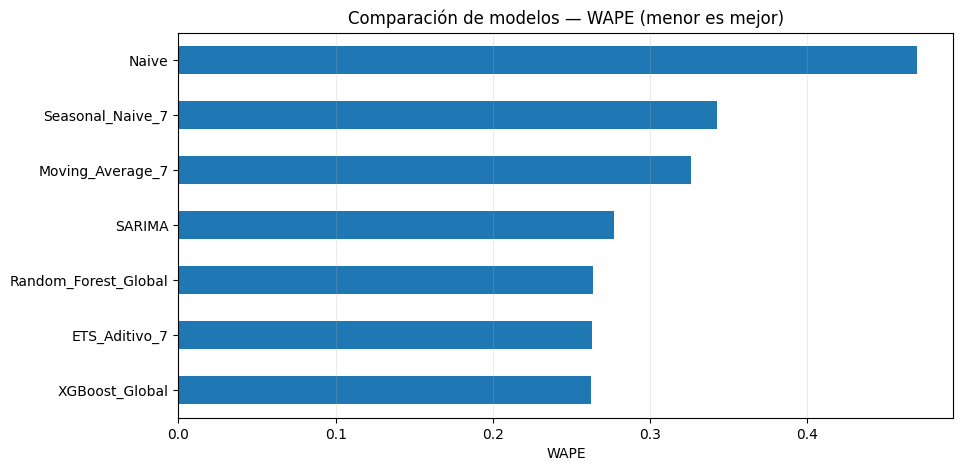

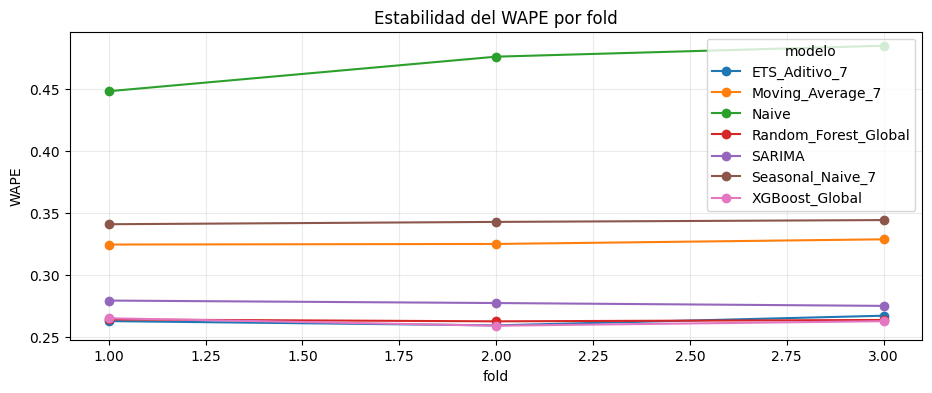

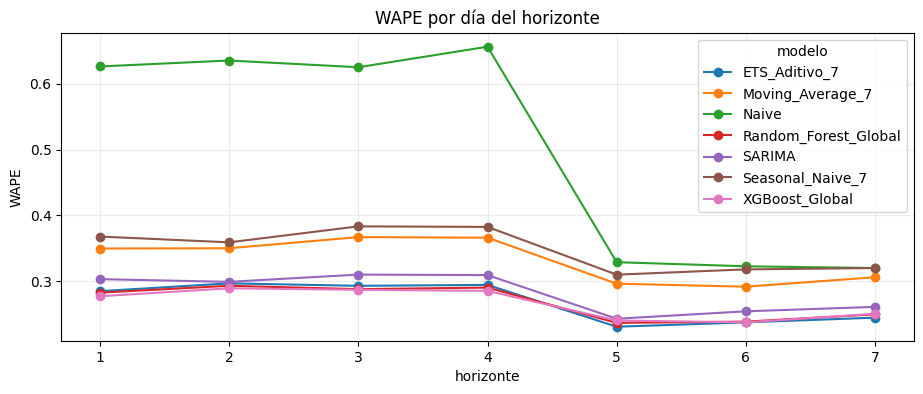

In [20]:
ax=metrics_model.sort_values("WAPE").plot(x="modelo",y="WAPE",kind="barh",figsize=(10,5),legend=False,
                                           title="Comparación de modelos — WAPE (menor es mejor)")
ax.set_xlabel("WAPE"); ax.set_ylabel(""); ax.grid(axis="x",alpha=.25); plt.show()

pivot=metrics_fold.pivot(index="fold",columns="modelo",values="WAPE")
pivot.plot(marker="o",figsize=(11,4),title="Estabilidad del WAPE por fold")
plt.ylabel("WAPE"); plt.grid(alpha=.25); plt.show()

pivot_h=metrics_horizon.pivot(index="horizonte",columns="modelo",values="WAPE")
pivot_h.plot(marker="o",figsize=(11,4),title="WAPE por día del horizonte")
plt.ylabel("WAPE"); plt.grid(alpha=.25); plt.show()

## 8A. Diagnóstico de errores por producto, tienda y fold

Estos diagnósticos preservan la lectura operativa del benchmark: un promedio global puede ocultar productos o tiendas donde un modelo falla de forma sistemática. Se presentan tablas y gráficos para identificar heterogeneidad y no elegir un modelo únicamente por una métrica agregada.

,modelo,fold,MAE,RMSE,WAPE,Bias,N
0,ETS_Aditivo_7,1,3.498127,4.600797,0.262911,0.003019,1120.0
1,ETS_Aditivo_7,2,3.461278,4.575546,0.259480,0.003040,1120.0
2,ETS_Aditivo_7,3,3.562135,4.692286,0.267256,0.010778,1120.0
3,Moving_Average_7,1,4.319005,5.527079,0.324606,-0.012683,1120.0
4,Moving_Average_7,2,4.336224,5.679852,0.325072,-0.002544,1120.0
5,Moving_Average_7,3,4.382653,5.732249,0.328816,0.000804,1120.0
6,Naive,1,5.962500,7.721838,0.448128,0.189371,1120.0
7,Naive,2,6.349107,8.228055,0.475971,0.220549,1120.0
8,Naive,3,6.461607,8.471538,0.484794,0.258106,1120.0
9,Random_Forest_Global,1,3.515849,4.614024,0.264243,0.004030,1120.0


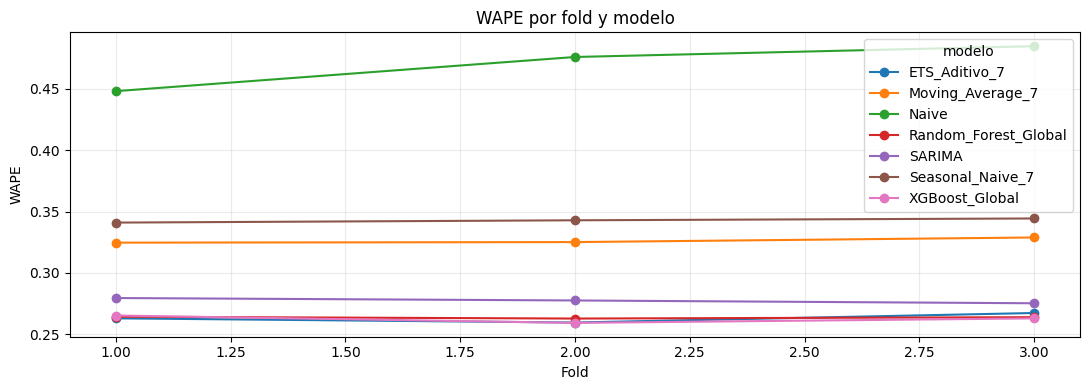

,modelo,id_producto,MAE,RMSE,WAPE,Bias,N
4,ETS_Aditivo_7,PROD_005,4.084920,5.322481,0.225301,-0.008722,420.0
5,ETS_Aditivo_7,PROD_006,3.787538,4.848797,0.233558,0.021183,420.0
6,ETS_Aditivo_7,PROD_007,4.172378,5.478284,0.237710,-0.022052,420.0
7,ETS_Aditivo_7,PROD_008,4.409801,5.750205,0.273860,0.035988,420.0
2,ETS_Aditivo_7,PROD_003,3.244187,4.149833,0.277507,0.004913,420.0
1,ETS_Aditivo_7,PROD_002,3.237211,4.194108,0.282315,0.009761,420.0
0,ETS_Aditivo_7,PROD_001,2.639041,3.355124,0.316323,0.008119,420.0
3,ETS_Aditivo_7,PROD_004,2.482365,3.162818,0.349981,-0.002336,420.0
12,Moving_Average_7,PROD_005,5.016667,6.349326,0.276691,-0.013526,420.0
13,Moving_Average_7,PROD_006,4.996599,6.216502,0.308115,0.006754,420.0


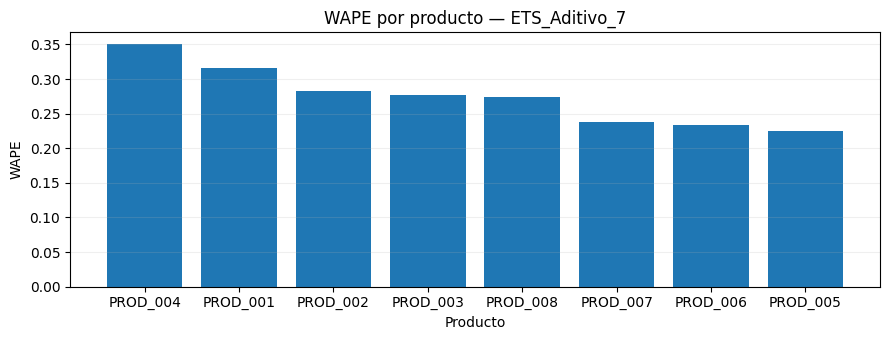

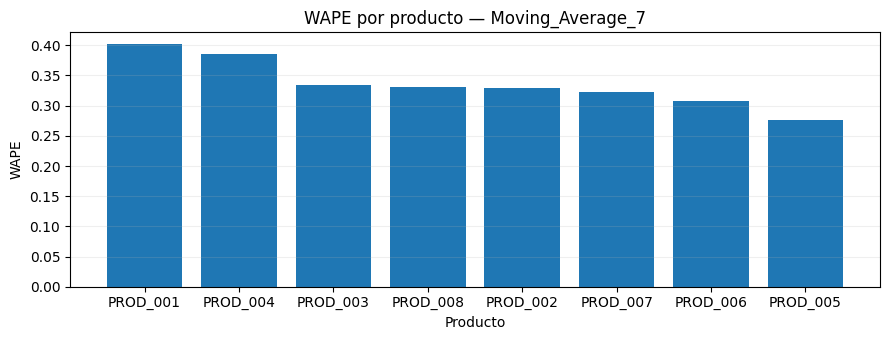

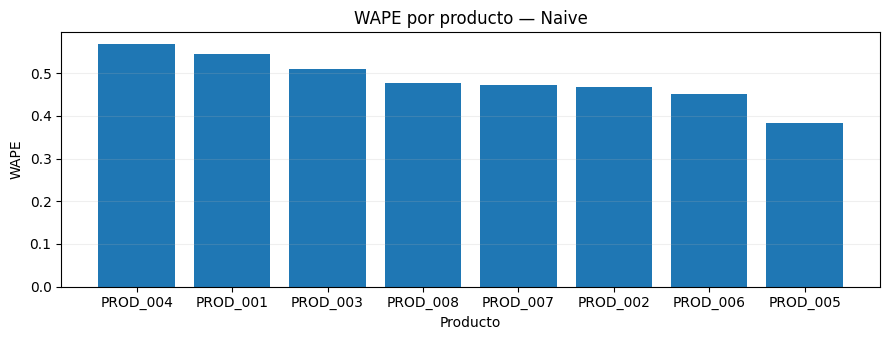

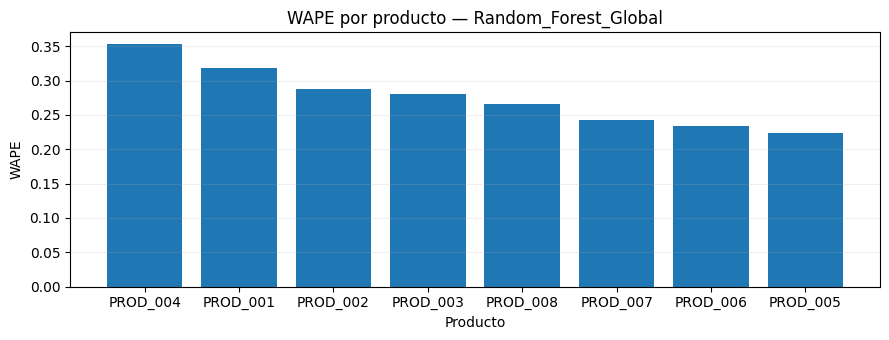

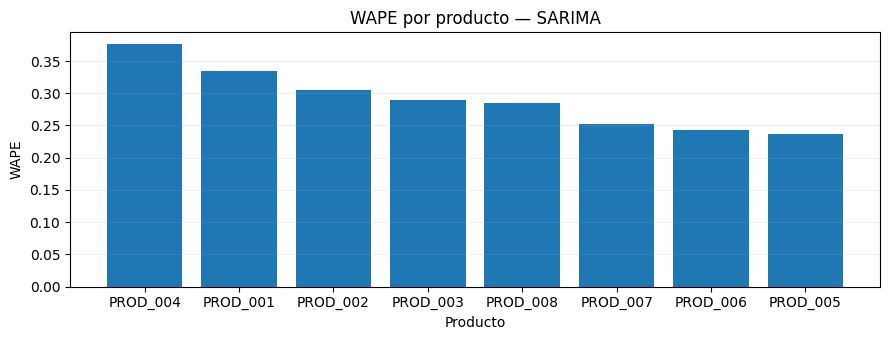

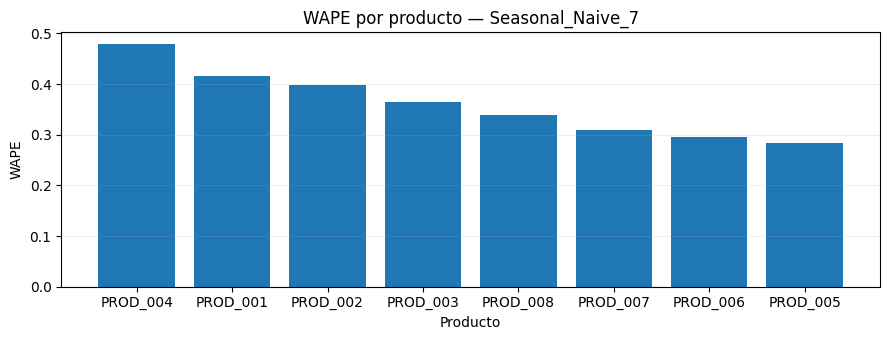

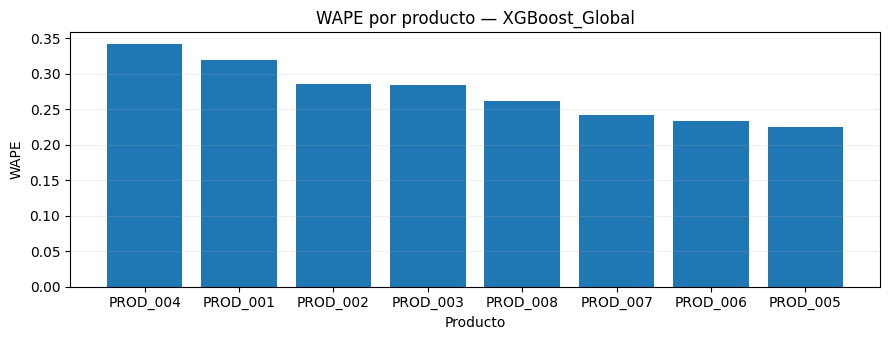

,modelo,id_tienda,MAE,RMSE,WAPE,Bias,N
15,ETS_Aditivo_7,STORE_16,4.587811,6.235324,0.220215,0.003971,168.0
18,ETS_Aditivo_7,STORE_19,3.115550,4.239322,0.223013,0.023983,168.0
4,ETS_Aditivo_7,STORE_05,3.392261,4.198075,0.225703,-0.016583,168.0
7,ETS_Aditivo_7,STORE_08,4.550860,6.267813,0.227272,-0.001214,168.0
2,ETS_Aditivo_7,STORE_03,3.717719,4.736780,0.227450,-0.036238,168.0
...,...,...,...,...,...,...,...
129,XGBoost_Global,STORE_10,3.331143,4.417068,0.300877,0.003040,168.0
120,XGBoost_Global,STORE_01,2.780972,3.495106,0.302593,0.026680,168.0
136,XGBoost_Global,STORE_17,2.402895,3.100782,0.343271,0.022085,168.0
128,XGBoost_Global,STORE_09,3.067284,4.112798,0.344454,0.036798,168.0


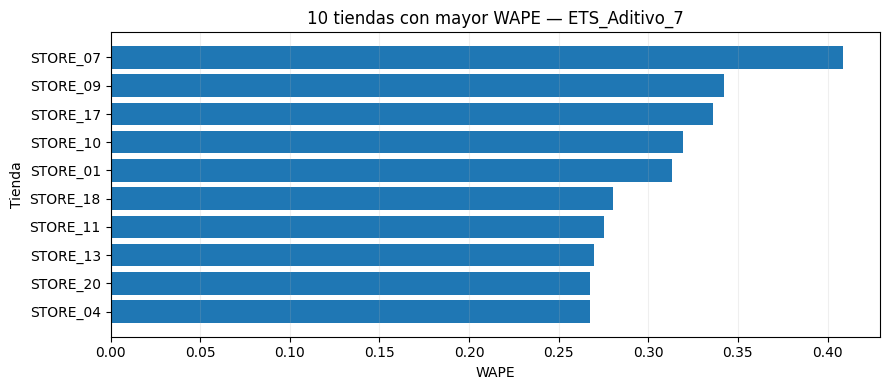

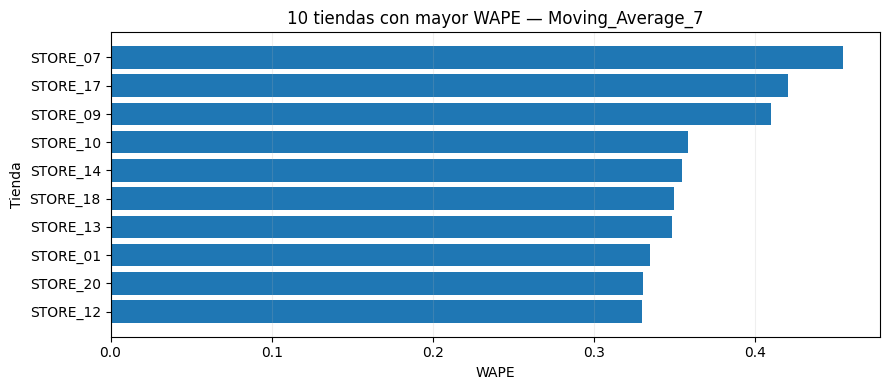

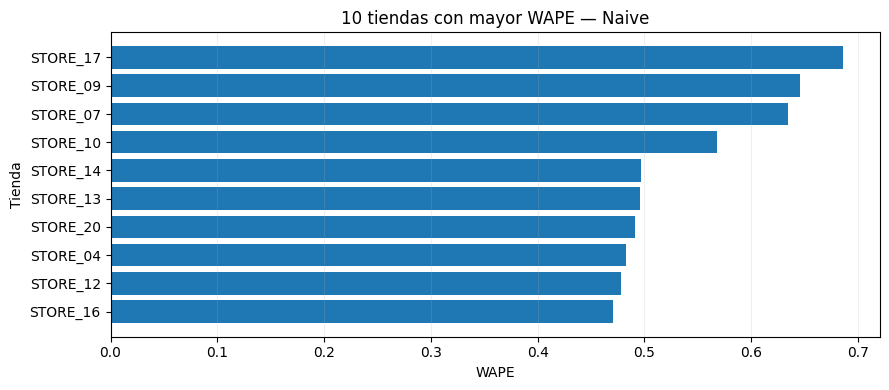

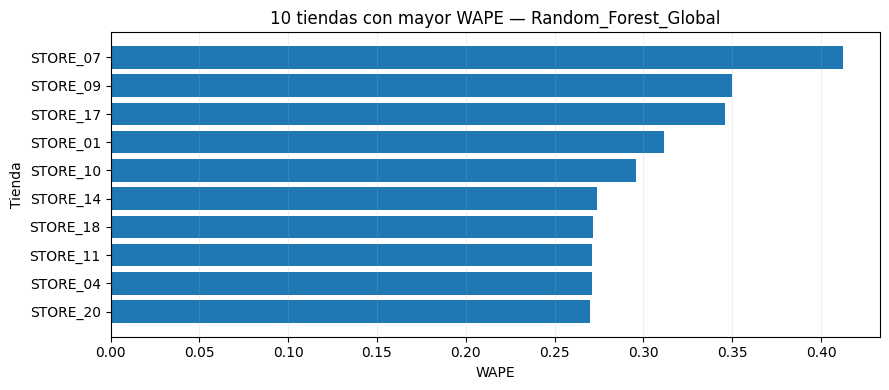

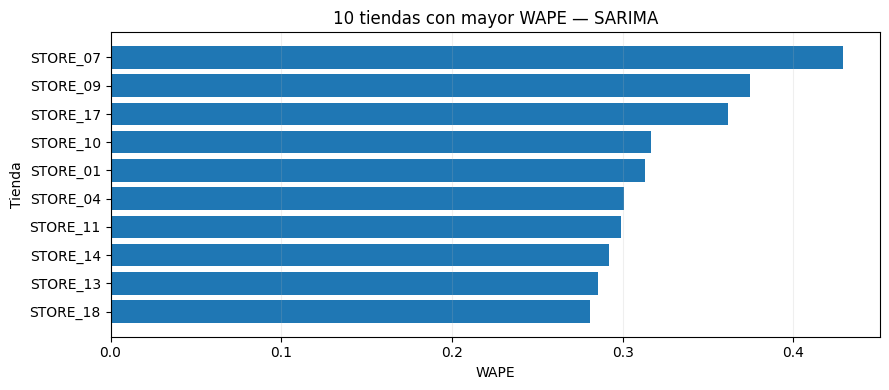

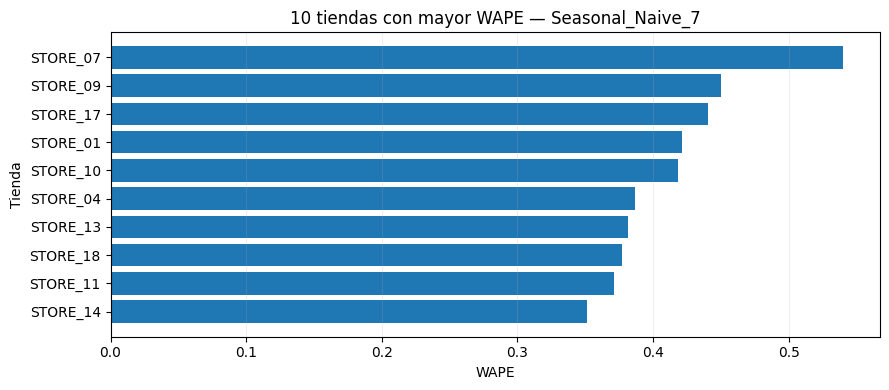

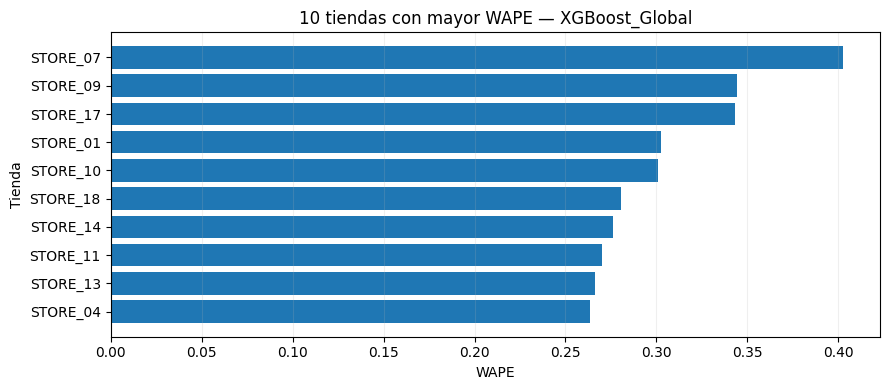

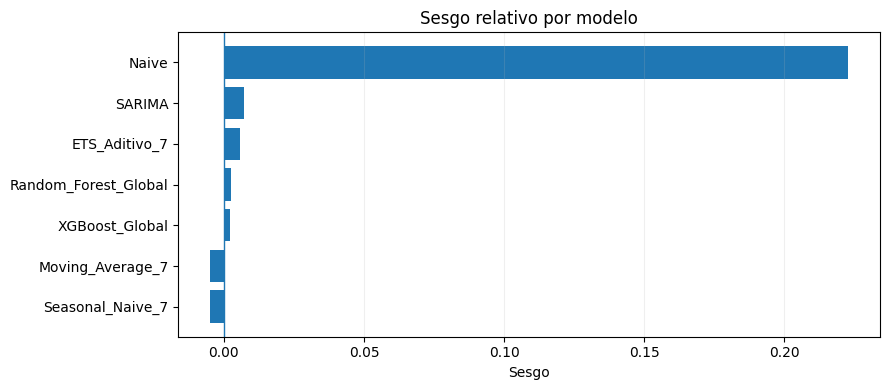

In [21]:
# Desempeño por fold: estabilidad temporal
fold_plot = metrics_fold.pivot(index="fold", columns="modelo", values="WAPE")
display(metrics_fold.sort_values(["modelo","fold"]))
ax = fold_plot.plot(marker="o", figsize=(11,4), title="WAPE por fold y modelo")
ax.set_ylabel("WAPE"); ax.set_xlabel("Fold"); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

# Desempeño por producto y modelo
product_metrics = (preds.groupby(["modelo","id_producto"])
                   .apply(lambda g: pd.Series(metrics(g.real,g.prediccion)), include_groups=False)
                   .reset_index())
display(product_metrics.sort_values(["modelo","WAPE"]))
for model_name in product_metrics["modelo"].unique():
    temp=product_metrics[product_metrics.modelo==model_name].sort_values("WAPE",ascending=False)
    fig,ax=plt.subplots(figsize=(9,3.5))
    ax.bar(temp["id_producto"].astype(str),temp["WAPE"])
    ax.set_title(f"WAPE por producto — {model_name}")
    ax.set_xlabel("Producto"); ax.set_ylabel("WAPE"); ax.grid(axis="y",alpha=.2)
    plt.tight_layout(); plt.show()

# Desempeño por tienda: tabla y top 10 tiendas con mayor WAPE por modelo
store_metrics = (preds.groupby(["modelo","id_tienda"])
                 .apply(lambda g: pd.Series(metrics(g.real,g.prediccion)), include_groups=False)
                 .reset_index())
display(store_metrics.sort_values(["modelo","WAPE"]))
for model_name in store_metrics["modelo"].unique():
    temp=store_metrics[store_metrics.modelo==model_name].nlargest(10,"WAPE").sort_values("WAPE")
    fig,ax=plt.subplots(figsize=(9,4))
    ax.barh(temp["id_tienda"].astype(str),temp["WAPE"])
    ax.set_title(f"10 tiendas con mayor WAPE — {model_name}")
    ax.set_xlabel("WAPE"); ax.set_ylabel("Tienda"); ax.grid(axis="x",alpha=.2)
    plt.tight_layout(); plt.show()

# Sesgo por modelo: positivo = sobrepronóstico, negativo = subpronóstico
bias_plot=metrics_model.sort_values("Bias")
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(bias_plot["modelo"],bias_plot["Bias"])
ax.axvline(0,linewidth=1)
ax.set_title("Sesgo relativo por modelo")
ax.set_xlabel("Sesgo"); ax.grid(axis="x",alpha=.2)
plt.tight_layout(); plt.show()


## 9. Interpretabilidad: importancia de variables en Random Forest y XGBoost

La importancia se calcula sobre los modelos globales de ML entrenados con el histórico disponible. En Random Forest se reporta importancia por disminución de impureza (MDI); en XGBoost se reporta ganancia (gain). Ambas son medidas internas del modelo, sensibles a correlación entre predictores y cardinalidad. **No representan efectos causales ni son comparables directamente entre algoritmos.**

Se agrupan las columnas one-hot por variable original para que la interpretación sea legible.

,variable,importance
11,mean_28,0.557694
3,dow,0.187126
12,mean_7,0.121986
14,std_7,0.025891
7,id_tienda,0.025337
10,lag_7,0.012953
15,tamaño_m2,0.011426
6,id_producto,0.009947
16,weekend,0.008282
9,lag_14,0.006833


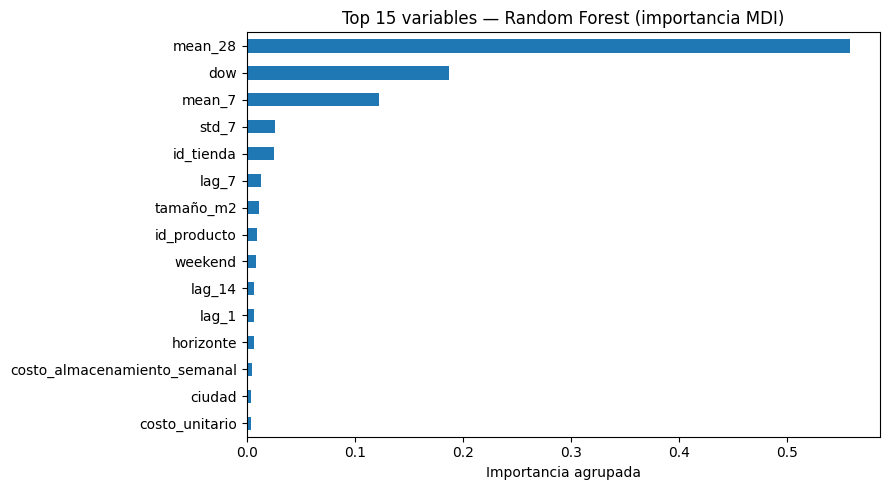

,variable,gain
11,media_28,17405.996094
7,id_tienda,7979.936195
2,dow_obj,5692.726562
12,media_7,4217.206055
4,fin_semana_obj,3789.794678
6,id_producto,2689.774490
0,ciudad,1900.916077
8,lag_1,1052.499512
1,desv_7,500.502075
9,lag_14,310.172516


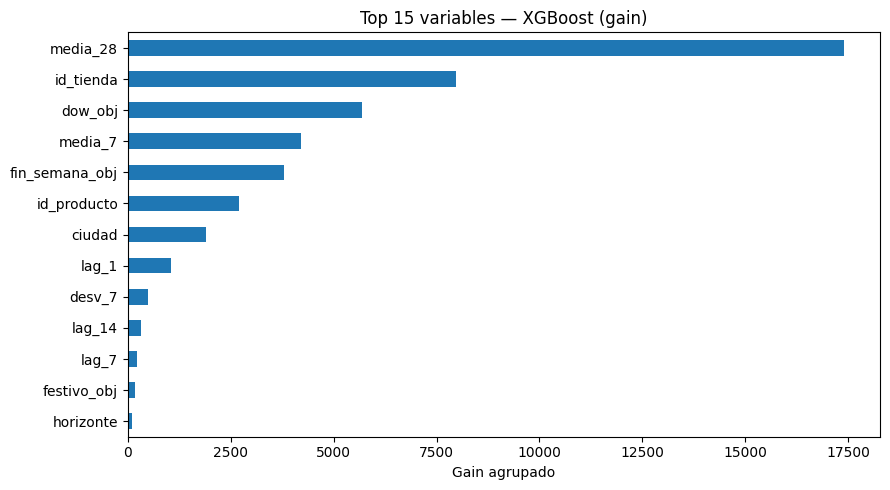

In [22]:
# Reentrenamiento global de RF y XGBoost para interpretación (no altera el modelo ETS desplegado).
OUT=Path('salidas_forecasting_integral')
OUT.mkdir(exist_ok=True)
rf_importance = pd.DataFrame()
xgb_importance = pd.DataFrame()

# Random Forest: agrupar importancia de columnas transformadas por variable fuente
rf_train_full = build_rf_examples(panel, panel["fecha"].max())
if not rf_train_full.empty:
    rf_final_interpret = make_rf_pipeline()
    rf_final_interpret.fit(rf_train_full[RF_FEATURES], rf_train_full["real"])
    prep = rf_final_interpret.named_steps["prep"]
    rf_model = rf_final_interpret.named_steps["model"]
    transformed_names = prep.get_feature_names_out()
    raw_imp = pd.DataFrame({"feature_encoded": transformed_names,
                            "importance": rf_model.feature_importances_})
    def source_feature(encoded_name):
        name = str(encoded_name)
        if name.startswith("cat__"):
            # cat__<feature>_<category> -> recuperar la categoría original más probable
            body=name[len("cat__"):]
            matches=[c for c in RF_CAT if body==c or body.startswith(c+"_")]
            return matches[0] if matches else body
        if name.startswith("num__"):
            return name[len("num__"):]
        return name
    raw_imp["variable"] = raw_imp["feature_encoded"].map(source_feature)
    rf_importance=(raw_imp.groupby("variable",as_index=False)["importance"].sum()
                   .sort_values("importance",ascending=False))
    display(rf_importance)
    fig,ax=plt.subplots(figsize=(9,5))
    rf_importance.head(15).sort_values("importance").plot(
        x="variable",y="importance",kind="barh",ax=ax,legend=False)
    ax.set_title("Top 15 variables — Random Forest (importancia MDI)")
    ax.set_xlabel("Importancia agrupada"); ax.set_ylabel("")
    plt.tight_layout(); plt.show()

# XGBoost: gain importance, agrupando variables categóricas codificadas
xgb_train_full = build_xgb_training(panel, panel["fecha"].max())
if not xgb_train_full.empty:
    xgb_final_interpret = make_xgb_pipeline()
    xgb_final_interpret.fit(xgb_train_full[XGB_NUM+XGB_CAT], xgb_train_full["target"])
    xgb_prep=xgb_final_interpret.named_steps["prep"]
    xgb_model=xgb_final_interpret.named_steps["model"]
    xgb_names=xgb_prep.get_feature_names_out()
    gain=xgb_model.get_booster().get_score(importance_type="gain")
    # XGBoost puede nombrar columnas como f0, f1... tras el ColumnTransformer.
    gain_rows=[]
    for key,value in gain.items():
        if key.startswith("f") and key[1:].isdigit():
            idx=int(key[1:])
            encoded=xgb_names[idx] if idx<len(xgb_names) else key
        else:
            encoded=key
        encoded=str(encoded)
        source=encoded.split("__",1)[-1]
        if source.startswith("id_tienda"): source="id_tienda"
        elif source.startswith("id_producto"): source="id_producto"
        elif source.startswith("ciudad"): source="ciudad"
        gain_rows.append({"variable":source,"gain":value})
    xgb_importance=(pd.DataFrame(gain_rows).groupby("variable",as_index=False)["gain"].sum()
                    .sort_values("gain",ascending=False))
    display(xgb_importance)
    fig,ax=plt.subplots(figsize=(9,5))
    xgb_importance.head(15).sort_values("gain").plot(
        x="variable",y="gain",kind="barh",ax=ax,legend=False)
    ax.set_title("Top 15 variables — XGBoost (gain)")
    ax.set_xlabel("Gain agrupado"); ax.set_ylabel("")
    plt.tight_layout(); plt.show()

# Exportar importancia para trazabilidad
if not rf_importance.empty:
    rf_importance.to_csv(OUT/"importancia_variables_random_forest.csv",index=False)
if not xgb_importance.empty:
    xgb_importance.to_csv(OUT/"importancia_variables_xgboost.csv",index=False)


## 10. Reentrenamiento del modelo seleccionado y forecast de 7 días

In [24]:
# Reentrena ETS aditivo de forma independiente para cada SKU–tienda con toda la historia.
last_date=panel.fecha.max()
future_dates=pd.date_range(last_date+pd.Timedelta(days=1),periods=HORIZON,freq="D")
future_rows=[]
fallback_count=0
for (store,product),g in panel.groupby(KEYS):
    g=g.sort_values("fecha")
    y=g.y.to_numpy(float)
    if len(y)<MIN_HISTORY:
        pred=np.resize(y[-7:],HORIZON)
        model_status="Seasonal_Naive_fallback"
        fallback_count+=1
    else:
        try:
            fit=ExponentialSmoothing(y,trend="add",damped_trend=True,
                                     seasonal="add",seasonal_periods=7,
                                     initialization_method="estimated").fit(
                                         optimized=True,use_brute=False)
            pred=np.asarray(fit.forecast(HORIZON)).clip(0)
            model_status="ETS_Aditivo_7"
        except Exception:
            pred=np.resize(y[-7:],HORIZON)
            model_status="Seasonal_Naive_fallback"
            fallback_count+=1
    for h,d in enumerate(future_dates,1):
        future_rows.append({"fecha":d,"id_tienda":store,"id_producto":product,
                            "horizonte":h,"demanda_pronosticada":float(pred[h-1]),
                            "modelo":model_status})
forecast_daily=pd.DataFrame(future_rows)
forecast_weekly=(forecast_daily.groupby(KEYS,as_index=False)
                 .agg(demanda_pronosticada_7d=("demanda_pronosticada","sum")))
print("Corte:",last_date.date(),"| Horizonte:",future_dates.min().date(),"a",future_dates.max().date())
print("Combinaciones:",forecast_weekly.shape[0],"| Fallbacks:",fallback_count)
display(forecast_daily.head(14))
display(forecast_weekly.head())

Corte: 2024-03-31 | Horizonte: 2024-04-01 a 2024-04-07
Combinaciones: 160 | Fallbacks: 0


,fecha,id_tienda,id_producto,horizonte,demanda_pronosticada,modelo
0,2024-04-01,STORE_01,PROD_001,1,5.245338,ETS_Aditivo_7
1,2024-04-02,STORE_01,PROD_001,2,5.762260,ETS_Aditivo_7
2,2024-04-03,STORE_01,PROD_001,3,4.820466,ETS_Aditivo_7
3,2024-04-04,STORE_01,PROD_001,4,5.418732,ETS_Aditivo_7
4,2024-04-05,STORE_01,PROD_001,5,9.096804,ETS_Aditivo_7
5,2024-04-06,STORE_01,PROD_001,6,10.468775,ETS_Aditivo_7
6,2024-04-07,STORE_01,PROD_001,7,8.458056,ETS_Aditivo_7
7,2024-04-01,STORE_01,PROD_002,1,8.646793,ETS_Aditivo_7
8,2024-04-02,STORE_01,PROD_002,2,8.866521,ETS_Aditivo_7
9,2024-04-03,STORE_01,PROD_002,3,7.624189,ETS_Aditivo_7


,id_tienda,id_producto,demanda_pronosticada_7d
0,STORE_01,PROD_001,49.270432
1,STORE_01,PROD_002,65.009762
2,STORE_01,PROD_003,61.682516
3,STORE_01,PROD_004,49.347908
4,STORE_01,PROD_005,75.050939


## 11. Exportación de experimentos y artefactos de despliegue

Se exportan predicciones y métricas de todos los modelos, además del pronóstico ETS que consume el pipeline de abastecimiento. El nombre y esquema del archivo ETS se mantienen compatibles con la etapa posterior.

In [25]:
OUT=Path("salidas_forecasting_integral")
OUT.mkdir(exist_ok=True)
preds.to_csv(OUT/"backtesting_todos_modelos.csv",index=False)
metrics_model.to_csv(OUT/"metricas_todos_modelos.csv",index=False)
metrics_fold.to_csv(OUT/"metricas_por_fold.csv",index=False)
metrics_horizon.to_csv(OUT/"metricas_por_horizonte.csv",index=False)
historical_benchmark.to_csv(OUT/"benchmark_historico_reportado.csv",index=False)
forecast_daily.to_csv(OUT/"forecast_ets_diario_7d.csv",index=False)
forecast_weekly.to_csv(OUT/"forecast_ets_semanal_sku_tienda.csv",index=False)
print("Archivos exportados en:",OUT.resolve())

# Descarga ZIP automática en Google Colab
if IN_COLAB:
    import shutil
    from google.colab import files
    files.download(shutil.make_archive(str(OUT), "zip", root_dir=OUT))

Archivos exportados en: /content/salidas_forecasting_integral


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones y decisión técnica

Completar después de ejecutar el notebook:

1. Modelo con menor WAPE en el backtesting homogéneo.
2. Diferencia de WAPE frente a ETS y frente a Seasonal Naive 7.
3. Estabilidad de cada modelo entre folds.
4. Comportamiento del sesgo y del RMSE.
5. Cobertura efectiva de predicciones y fallbacks.
6. Confirmación de ETS como modelo desplegado o justificación documentada de un eventual cambio.

**Decisión de despliegue vigente:** ETS aditivo por SKU–tienda, con Seasonal Naive 7 como respaldo de ajuste. XGBoost se conserva como challenger, no como modelo productivo actual.

### Limitaciones
- Solo se dispone de aproximadamente tres meses de historia; no se valida estacionalidad anual.
- Las ventas observadas pueden estar censuradas por quiebres de inventario.
- Completar fechas ausentes como cero es un supuesto, no una verdad observada.
- Tres folds de siete días ofrecen evidencia limitada sobre estabilidad.
- Los resultados dependen de la misma cobertura de series y fechas; comparar métricas de ejecuciones con cobertura diferente puede inducir conclusiones erróneas.